# Digital Image Processing Lab — Lab Task 05
## Spatial Filtering and Convolution

| | |
|---|---|
| Name | Sahadat Ali |
| Roll No | 2024-SE-36 |
| University / Department | The University of Azad Jammu and Kashmir — Department of Software Engineering |
| Lab Instructor | Engr. Fahad Nisar |
| Semester / Session | Fifth / 2024-28 (SE) |
| Assigned / Due | November 13, 2026 / November 20, 2026, 11:59 PM |

## Lab Objectives

1. Implement two-dimensional **convolution from first principles** (nested pixel loops, flipped kernel, reflect padding).
2. **Verify** the hand-written convolution against OpenCV and report the largest difference.
3. Generate **Gaussian** and **salt-and-pepper** noise with our own functions (`seed=5`, reproducible).
4. Apply **mean, Gaussian and median** filters at 3×3, 5×5 and 7×7 to noisy images.
5. Judge every filtered image against the **clean original** (rule R6), using figures and numbers.
6. Check the filtering rules **R1–R6** and complete the two **dry-run exercises** by hand.

**Filtering rules used throughout:** R1 same size + reflect padding · R2 float64 inside, `uint8` (round + clip) only at the end · R3 smoothing weights sum to 1 · R4 odd kernel sizes 3/5/7 · R5 `seed=5` · R6 judge against the clean original.

## Required Libraries and Imports

In [1]:
import os
import hashlib

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import skimage
from skimage import data
from skimage.metrics import structural_similarity

os.makedirs("figures", exist_ok=True)      # folder for the saved comparison grids

print("NumPy        :", np.__version__)
print("OpenCV       :", cv2.__version__)
print("Matplotlib   :", matplotlib.__version__)
print("scikit-image :", skimage.__version__)

NumPy        : 2.4.6
OpenCV       : 5.0.0
Matplotlib   : 3.10.0
scikit-image : 0.25.2


## Task 1 — Load the three test images (originals stay unchanged)

**Problem statement:** Load `camera`, `coins` and `chelsea` (converted to grayscale) from `skimage.data` as the three test images. Keep the originals unchanged.

**Explanation:** `camera` and `coins` are already 8-bit grayscale. `chelsea` is an RGB photograph, so it is converted with `cv2.cvtColor`. To *guarantee* the originals are never modified, each array is made read-only and a SHA-256 fingerprint is stored; the fingerprint is checked again at the end of the notebook.

In [2]:
camera  = data.camera()                                      # grayscale uint8
coins   = data.coins()                                       # grayscale uint8
chelsea = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY)   # RGB -> grayscale uint8

originals = {"camera": camera, "coins": coins, "chelsea": chelsea}

fingerprints = {}
for name, im in originals.items():
    im.setflags(write=False)                                 # read-only: cannot be changed by accident
    fingerprints[name] = hashlib.sha256(im.tobytes()).hexdigest()
    print(f"{name:8s} shape={im.shape}  dtype={im.dtype}  min={im.min():3d}  max={im.max():3d}  "
          f"writeable={im.flags.writeable}  sha256[:12]={fingerprints[name][:12]}")

camera   shape=(512, 512)  dtype=uint8  min=  0  max=255  writeable=False  sha256[:12]=5cb24482a534
coins    shape=(303, 384)  dtype=uint8  min=  1  max=252  writeable=False  sha256[:12]=e080cc03805f
chelsea  shape=(300, 451)  dtype=uint8  min=  4  max=194  writeable=False  sha256[:12]=cd822d0a5b86


## Task 2 — `conv2d_loop` and verification against OpenCV

**Problem statement:** Implement `conv2d_loop(img, kernel)` with nested pixel loops. Flip the kernel, pad borders with reflect padding and return a float64 array the same size as the input (R1, R2). Verify it against OpenCV on at least one test image and report the largest difference.

**Explanation:**
* *True convolution* = correlation with the kernel **flipped in both directions** (`kernel[::-1, ::-1]`).
* `np.pad(..., mode="reflect")` mirrors the image about its edge pixel; this is the same border rule as OpenCV's `BORDER_REFLECT_101` (the default of `cv2.blur`, `cv2.GaussianBlur`, `cv2.filter2D`).
* Every output pixel is a weighted sum computed in float64. The helper `to_uint8` rounds and clips to 0–255 **only at the very end** (R2).
* `cv2.filter2D` actually computes *correlation*, so to get true convolution from OpenCV we hand it the flipped kernel.

In [3]:
def to_uint8(x):
    """R2: convert float64 -> uint8 only at the end, with round and clip to 0-255."""
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)


def conv2d_loop(img, kernel):
    """True 2-D convolution using nested pixel loops (R1, R2).

    1. flip the kernel (convolution, not correlation)
    2. pad the borders with reflect padding
    3. each output pixel = weighted sum of its neighbourhood, in float64
    Returns a float64 array with the same size as `img`.
    """
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("kernel dimensions must be odd")

    flipped = kernel[::-1, ::-1]                       # flip rows AND columns
    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")   # R1

    height, width = img.shape
    out = np.zeros((height, width), dtype=np.float64)
    for i in range(height):
        for j in range(width):
            window = padded[i:i + kh, j:j + kw]        # neighbourhood of pixel (i, j)
            out[i, j] = np.sum(window * flipped)       # weighted sum
    return out


# A tiny hand-checkable test first: an impulse convolved with an asymmetric kernel
# must reproduce the kernel itself (the impulse response) - this only works if the flip is done right.
impulse = np.zeros((5, 5)); impulse[2, 2] = 1.0
k_test = np.arange(1, 10, dtype=np.float64).reshape(3, 3)
print("conv2d_loop(impulse, kernel)[1:4, 1:4] =\n", conv2d_loop(impulse, k_test)[1:4, 1:4])
print("kernel =\n", k_test)

conv2d_loop(impulse, kernel)[1:4, 1:4] =
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
kernel =
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]


**Verification on a real image (`camera`).** An *asymmetric* kernel is used on purpose: with a symmetric kernel, flipping makes no difference and the test would prove nothing. The comparison is done in float64 (no rounding at all), then the practical `uint8` case (3×3 mean vs `cv2.blur`) is checked separately.

In [4]:
asym = np.array([[1, 2, 3],
                 [4, 5, 6],
                 [7, 8, 9]], dtype=np.float64) / 45.0          # asymmetric, weights sum to 1

mine      = conv2d_loop(camera, asym)
cv_conv   = cv2.filter2D(camera.astype(np.float64), -1, asym[::-1, ::-1], borderType=cv2.BORDER_REFLECT_101)
cv_corr   = cv2.filter2D(camera.astype(np.float64), -1, asym,             borderType=cv2.BORDER_REFLECT_101)

print("(a) float64, asymmetric kernel, camera image")
print(f"    max |conv2d_loop - OpenCV (kernel flipped)| = {np.max(np.abs(mine - cv_conv)):.3e}   <- agrees")
print(f"    max |conv2d_loop - OpenCV (NOT flipped)|    = {np.max(np.abs(mine - cv_corr)):.3f}   <- flipping really matters")
print(f"    output dtype = {mine.dtype}, shape = {mine.shape} (input shape {camera.shape})")

# (b) the practical uint8 case: 3x3 mean with our loop vs cv2.blur
mean3 = np.full((3, 3), 1 / 9)
loop_u8 = to_uint8(conv2d_loop(camera, mean3))
cv_u8   = cv2.blur(camera, (3, 3))
diff = np.abs(loop_u8.astype(int) - cv_u8.astype(int))
print("\n(b) 3x3 mean on camera: conv2d_loop (rounded to uint8) vs cv2.blur")
print(f"    largest difference = {diff.max()} grey level(s); pixels that differ = {np.count_nonzero(diff)} of {diff.size}")
print("    -> agreement within rounding" if diff.max() <= 1 else "    -> MISMATCH")
assert np.max(np.abs(mine - cv_conv)) < 1e-9 and diff.max() <= 1

(a) float64, asymmetric kernel, camera image
    max |conv2d_loop - OpenCV (kernel flipped)| = 1.137e-13   <- agrees
    max |conv2d_loop - OpenCV (NOT flipped)|    = 83.289   <- flipping really matters
    output dtype = float64, shape = (512, 512) (input shape (512, 512))

(b) 3x3 mean on camera: conv2d_loop (rounded to uint8) vs cv2.blur
    largest difference = 0 grey level(s); pixels that differ = 0 of 262144
    -> agreement within rounding


## Task 3 — Noise generation and reproducibility (R5)

**Problem statement:** Implement `add_gaussian_noise(img, sigma=20, seed=5)` and `add_salt_pepper(img, amount=0.05, seed=5)` ourselves, with `seed=5` (R5).

**Explanation:**
* **Gaussian noise:** add zero-mean normal noise with standard deviation `sigma` to the image in float64, then round and clip (R2).
* **Salt-and-pepper:** draw one uniform random number per pixel; the lowest `amount/2` fraction becomes black (pepper, 0) and the highest `amount/2` fraction becomes white (salt, 255), so about `amount` of all pixels are corrupted.
* A fresh `np.random.default_rng(seed)` is created *inside* each call, so the same seed always gives the same noise.

In [5]:
def add_gaussian_noise(img, sigma=20, seed=5):
    """Additive zero-mean Gaussian noise (std = sigma); float64 inside, uint8 out (R2, R5)."""
    rng = np.random.default_rng(seed)
    noise = rng.normal(loc=0.0, scale=sigma, size=img.shape)
    return to_uint8(img.astype(np.float64) + noise)


def add_salt_pepper(img, amount=0.05, seed=5):
    """Salt-and-pepper noise: `amount` of the pixels become 0 or 255 (half each) (R5)."""
    rng = np.random.default_rng(seed)
    out = img.copy()
    u = rng.random(img.shape)
    out[u < amount / 2] = 0              # pepper
    out[u > 1 - amount / 2] = 255        # salt
    return out


def make_noisy_set():
    noisy_set = {}
    for name, im in originals.items():
        noisy_set[(name, "gaussian")]    = add_gaussian_noise(im, sigma=20, seed=5)
        noisy_set[(name, "salt_pepper")] = add_salt_pepper(im, amount=0.05, seed=5)
    return noisy_set


noisy = make_noisy_set()                      # first run
for (name, kind), im in noisy.items():
    clean = originals[name]
    if kind == "gaussian":
        print(f"{name:8s} gaussian    : std of (noisy - clean) = {np.std(im.astype(float) - clean):5.2f}   (sigma = 20, a little less because of clipping)")
    else:
        print(f"{name:8s} salt_pepper : corrupted pixels       = {np.mean(im != clean) * 100:5.2f}%  (amount = 5%)")

camera   gaussian    : std of (noisy - clean) = 19.34   (sigma = 20, a little less because of clipping)
camera   salt_pepper : corrupted pixels       =  5.01%  (amount = 5%)
coins    gaussian    : std of (noisy - clean) = 19.79   (sigma = 20, a little less because of clipping)
coins    salt_pepper : corrupted pixels       =  4.99%  (amount = 5%)
chelsea  gaussian    : std of (noisy - clean) = 19.97   (sigma = 20, a little less because of clipping)
chelsea  salt_pepper : corrupted pixels       =  5.02%  (amount = 5%)


**Reproducibility check (R5).** The noisy images are regenerated from scratch with `seed=5` and compared with the first run using `np.array_equal`. SHA-256 fingerprints are printed too, so they can be compared after a kernel restart.

In [6]:
noisy_again = make_noisy_set()               # regenerate with the same seed
for key in noisy:
    same = np.array_equal(noisy[key], noisy_again[key])
    print(f"{key[0]:8s} {key[1]:12s} identical on regeneration: {same}   sha256[:12] = {hashlib.sha256(noisy[key].tobytes()).hexdigest()[:12]}")
    assert same

different_seed = add_gaussian_noise(camera, sigma=20, seed=6)
print("\nsanity check - a different seed (6) gives different noise:", not np.array_equal(different_seed, noisy[("camera", "gaussian")]))

camera   gaussian     identical on regeneration: True   sha256[:12] = e4857555cfa9
camera   salt_pepper  identical on regeneration: True   sha256[:12] = a55bffed7e42
coins    gaussian     identical on regeneration: True   sha256[:12] = 24184f5e895e
coins    salt_pepper  identical on regeneration: True   sha256[:12] = 8d835cf7a78e
chelsea  gaussian     identical on regeneration: True   sha256[:12] = 45dc14c084df
chelsea  salt_pepper  identical on regeneration: True   sha256[:12] = f94d3c17af86

sanity check - a different seed (6) gives different noise: True


## Task 4 — Kernels and the three filters, with rule checks R1–R4

**Problem statement:** Build the mean, Gaussian and median filters for sizes 3, 5 and 7. Smoothing weights must sum to 1 (R3); even kernel sizes must be rejected (R4); outputs keep the input size and use reflect padding (R1).

**Explanation:**
* **Mean kernel:** every weight is `1/size²`.
* **Gaussian kernel:** the outer product of OpenCV's 1-D discrete Gaussian (`cv2.getGaussianKernel(size, 0)`), which are exactly the weights `cv2.GaussianBlur(..., sigmaX=0)` uses. At 3×3 this is the classic 1-2-1 ÷ 16 kernel.
* **Median:** `cv2.medianBlur`. OpenCV's median pads with *replicate* (not reflect) borders internally, so to obey R1 the image is first padded with `BORDER_REFLECT_101` and the padding is cropped off afterwards. Only the outermost pixels are affected; this is verified below.
* `check_size` rejects even sizes (and anything outside 3/5/7) before any work is done.

In [7]:
VALID_SIZES = (3, 5, 7)

def check_size(size):
    """R4: kernel sizes must be odd (3, 5 or 7)."""
    if size % 2 == 0:
        raise ValueError(f"kernel size {size} is even - kernel sizes must be odd (R4)")
    if size not in VALID_SIZES:
        raise ValueError(f"kernel size {size} not allowed - use 3, 5 or 7")


def mean_kernel(size):
    check_size(size)
    return np.full((size, size), 1.0 / size ** 2)            # R3: weights sum to 1


def gaussian_kernel(size):
    check_size(size)
    g = cv2.getGaussianKernel(size, 0)                        # 1-D column, sums to 1
    return g @ g.T                                            # 2-D = outer product, sums to 1


def mean_filter(img, size, own_loop=False):
    kernel = mean_kernel(size)
    if own_loop:
        return to_uint8(conv2d_loop(img, kernel))            # our own convolution
    return cv2.blur(img, (size, size))                        # OpenCV (reflect-101 border)


def gaussian_filter(img, size):
    check_size(size)
    return cv2.GaussianBlur(img, (size, size), 0)             # OpenCV (reflect-101 border)


def median_filter(img, size):
    check_size(size)
    r = size // 2
    padded = cv2.copyMakeBorder(img, r, r, r, r, cv2.BORDER_REFLECT_101)   # R1: reflect padding
    return np.ascontiguousarray(cv2.medianBlur(padded, size)[r:-r, r:-r])


# ---- R3: print every smoothing kernel's weight sum BEFORE using it ----
print("R3 - kernel weight sums")
for size in VALID_SIZES:
    for label, k in (("mean", mean_kernel(size)), ("gaussian", gaussian_kernel(size))):
        total = k.sum()
        ok = np.isclose(total, 1.0)
        print(f"  {label:8s} {size}x{size}: sum = {total:.12f}  {'OK (= 1)' if ok else 'FAIL'}")
        assert ok

print("\nGaussian kernels (integer form x denominator):")
for size, denom in ((3, 16), (5, 256), (7, 4096)):
    print(f"  {size}x{size}  (divide by {denom}):\n{np.round(gaussian_kernel(size) * denom).astype(int)}\n")

R3 - kernel weight sums
  mean     3x3: sum = 1.000000000000  OK (= 1)
  gaussian 3x3: sum = 1.000000000000  OK (= 1)
  mean     5x5: sum = 1.000000000000  OK (= 1)
  gaussian 5x5: sum = 1.000000000000  OK (= 1)
  mean     7x7: sum = 1.000000000000  OK (= 1)
  gaussian 7x7: sum = 1.000000000000  OK (= 1)

Gaussian kernels (integer form x denominator):
  3x3  (divide by 16):
[[1 2 1]
 [2 4 2]
 [1 2 1]]

  5x5  (divide by 256):
[[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]

  7x7  (divide by 4096):
[[  4  14  28  36  28  14   4]
 [ 14  49  98 126  98  49  14]
 [ 28  98 196 252 196  98  28]
 [ 36 126 252 324 252 126  36]
 [ 28  98 196 252 196  98  28]
 [ 14  49  98 126  98  49  14]
 [  4  14  28  36  28  14   4]]



**Check that our own convolution matches OpenCV for the mean filter (all images, all sizes) and for the Gaussian filter.** The mean filter is applied once with `conv2d_loop` and once with `cv2.blur`; the two must agree within rounding.

In [8]:
print("Mean filter: conv2d_loop (rounded) vs cv2.blur  [largest difference in grey levels]")
for name, im in originals.items():
    row = []
    for size in VALID_SIZES:
        d = np.abs(mean_filter(im, size, own_loop=True).astype(int) - mean_filter(im, size).astype(int)).max()
        row.append(f"{size}x{size}: {d}")
        assert d <= 1
    print(f"  {name:8s}", "   ".join(row))

print("\nGaussian filter: conv2d_loop with our Gaussian kernel vs cv2.GaussianBlur (camera)")
for size in VALID_SIZES:
    d = np.abs(to_uint8(conv2d_loop(camera, gaussian_kernel(size))).astype(int) - gaussian_filter(camera, size).astype(int)).max()
    print(f"  {size}x{size}: largest difference = {d}")
    assert d <= 1

Mean filter: conv2d_loop (rounded) vs cv2.blur  [largest difference in grey levels]
  camera   3x3: 0   5x5: 0   7x7: 0
  coins    3x3: 0   5x5: 0   7x7: 0
  chelsea  3x3: 0   5x5: 0   7x7: 0

Gaussian filter: conv2d_loop with our Gaussian kernel vs cv2.GaussianBlur (camera)
  3x3: largest difference = 1
  5x5: largest difference = 1
  7x7: largest difference = 1


**Median border check and independent verification.** The reflect-padded `median_filter` is compared with a plain NumPy median (`np.pad(..., "reflect")` + `np.median`) on a small crop, and with the unpadded `cv2.medianBlur` to show that only the outermost pixels differ.

In [9]:
crop = camera[100:140, 200:250]
for size in VALID_SIZES:
    r = size // 2
    p = np.pad(crop, r, mode="reflect")
    reference = np.array([[np.median(p[i:i + size, j:j + size]) for j in range(crop.shape[1])]
                          for i in range(crop.shape[0])]).astype(np.uint8)
    assert np.array_equal(median_filter(crop, size), reference)
print("median_filter == plain NumPy reflect-padded median for 3x3, 5x5, 7x7 on a test crop: True")

plain = cv2.medianBlur(camera, 3)
mine_med = median_filter(camera, 3)
interior_equal = np.array_equal(plain[1:-1, 1:-1], mine_med[1:-1, 1:-1])
print("3x3: interior identical to cv2.medianBlur:", interior_equal,
      "| pixels that differ (all on the 1-pixel border):", np.count_nonzero(plain != mine_med))

median_filter == plain NumPy reflect-padded median for 3x3, 5x5, 7x7 on a test crop: True
3x3: interior identical to cv2.medianBlur: True | pixels that differ (all on the 1-pixel border): 1018


**R4 — an even kernel size is rejected.** OpenCV raises an error for `cv2.medianBlur(img, 4)`, and our own wrappers raise `ValueError`. A short experiment afterwards shows *why* even kernels are a problem: a single white pixel blurred by a 3×3 and a 4×4 mean.

In [10]:
try:
    cv2.medianBlur(camera, 4)
    print("cv2.medianBlur(camera, 4) did NOT raise an error")
except cv2.error as e:
    print("cv2.medianBlur(camera, 4) raised cv2.error ->", " ".join(str(e).split())[:200])

for fn in (mean_filter, gaussian_filter, median_filter):
    try:
        fn(camera, 4)
        print(fn.__name__, "accepted size 4 (bad)")
    except ValueError as e:
        print(f"{fn.__name__}(camera, 4) raised ValueError -> {e}")

# Why odd? One white pixel at (4, 4) in a 9x9 black image:
dot = np.zeros((9, 9), dtype=np.uint8); dot[4, 4] = 255
for k in (3, 4):
    spread = cv2.blur(dot, (k, k))
    rows, cols = np.nonzero(spread)
    print(f"\n{k}x{k} mean of a single white pixel at (4, 4): bright rows {rows.min()}..{rows.max()}, cols {cols.min()}..{cols.max()}"
          f"  -> block centre = ({(rows.min() + rows.max()) / 2}, {(cols.min() + cols.max()) / 2})")

cv2.medianBlur(camera, 4) raised cv2.error -> OpenCV(5.0.0) /io/opencv/modules/imgproc/src/median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksize % 2 == 1) && (_src0.dims() <= 2 ) in function 'medianBlur'
mean_filter(camera, 4) raised ValueError -> kernel size 4 is even - kernel sizes must be odd (R4)
gaussian_filter(camera, 4) raised ValueError -> kernel size 4 is even - kernel sizes must be odd (R4)
median_filter(camera, 4) raised ValueError -> kernel size 4 is even - kernel sizes must be odd (R4)

3x3 mean of a single white pixel at (4, 4): bright rows 3..5, cols 3..5  -> block centre = (4.0, 4.0)

4x4 mean of a single white pixel at (4, 4): bright rows 3..6, cols 3..6  -> block centre = (4.5, 4.5)


## Task 5 — Apply mean, Gaussian and median filters (3×3, 5×5, 7×7) to every noisy image

**Problem statement:** Apply the three filters at 3×3, then repeat at 5×5 and 7×7, on every noisy image; judge every result against the **clean original** (R6).

**Explanation:** Six noisy images (3 images × 2 noise types) × 3 filters × 3 sizes = **54 filtered images**. Quality is measured with PSNR (dB, higher is better) and SSIM (0–1, higher is better). The metric functions are always called with the *clean original* as the reference; the noisy image only appears as a baseline row to show how much each filter improved.

In [11]:
SIZES = (3, 5, 7)
FILTERS = {"Mean": mean_filter, "Gaussian": gaussian_filter, "Median": median_filter}

filtered = {}                      # (image, noise, filter, size) -> uint8 image
for (name, kind), noisy_img in noisy.items():
    for fname, func in FILTERS.items():
        for size in SIZES:
            filtered[(name, kind, fname, size)] = func(noisy_img, size)
print(len(filtered), "filtered images created")


def psnr(clean, test):
    mse = np.mean((clean.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

def ssim(clean, test):
    return structural_similarity(clean, test, data_range=255)

# R6: every score below compares against originals[name] (the clean image), never against the noisy image.
psnr_table, ssim_table = {}, {}
for (name, kind), noisy_img in noisy.items():
    clean = originals[name]
    psnr_table[(name, kind)] = {"Noisy": psnr(clean, noisy_img)}
    ssim_table[(name, kind)] = {"Noisy": ssim(clean, noisy_img)}
    for fname in FILTERS:
        for size in SIZES:
            out = filtered[(name, kind, fname, size)]
            psnr_table[(name, kind)][f"{fname[:4]}{size}"] = psnr(clean, out)
            ssim_table[(name, kind)][f"{fname[:4]}{size}"] = ssim(clean, out)

cols = list(next(iter(psnr_table.values())).keys())
def show_table(title, table, fmt):
    print(title)
    print(f"{'image / noise':<22}" + "".join(f"{c:>8}" for c in cols) + "   best")
    for (name, kind), row in table.items():
        best = max((c for c in cols if c != "Noisy"), key=lambda c: row[c])
        print(f"{name + ' / ' + kind:<22}" + "".join(f"{row[c]:>8{fmt}}" for c in cols) + f"   {best}")
    print()

show_table("PSNR vs CLEAN original (dB, higher = closer to the original)", psnr_table, ".2f")
show_table("SSIM vs CLEAN original (1.0 = identical)", ssim_table, ".3f")

54 filtered images created
PSNR vs CLEAN original (dB, higher = closer to the original)
image / noise            Noisy   Mean3   Mean5   Mean7   Gaus3   Gaus5   Gaus7   Medi3   Medi5   Medi7   best
camera / gaussian        22.40   27.37   26.17   24.85   27.99   27.81   26.95   26.93   26.83   25.79   Gaus3
camera / salt_pepper     17.69   24.83   25.09   24.25   24.71   25.65   25.67   30.09   27.83   26.22   Medi3
coins / gaussian         22.20   25.86   24.03   22.78   26.79   26.02   24.87   25.98   25.34   24.48   Gaus3
coins / salt_pepper      18.11   24.10   23.37   22.38   24.36   24.59   24.04   28.31   26.26   25.14   Medi3
chelsea / gaussian       22.12   29.55   29.56   28.75   29.46   30.37   30.29   28.28   29.09   28.74   Gaus5
chelsea / salt_pepper    18.73   27.00   28.31   28.05   26.50   28.11   28.82   33.88   30.97   29.69   Medi3

SSIM vs CLEAN original (1.0 = identical)
image / noise            Noisy   Mean3   Mean5   Mean7   Gaus3   Gaus5   Gaus7   Medi3   Medi5

**Rule compliance checks R1 / R2 on all 54 outputs:** every filtered image must be `uint8`, within 0–255 and the same shape as its input.

In [12]:
def check_output(out, reference):
    return (out.dtype == np.uint8 and out.shape == reference.shape
            and int(out.min()) >= 0 and int(out.max()) <= 255)

bad = [k for k, v in filtered.items() if not check_output(v, originals[k[0]])]
print(f"outputs checked      : {len(filtered)}")
print(f"all dtype uint8      : {all(v.dtype == np.uint8 for v in filtered.values())}")
print(f"global min / max     : {min(int(v.min()) for v in filtered.values())} / {max(int(v.max()) for v in filtered.values())}")
print(f"all shapes preserved : {all(v.shape == originals[k[0]].shape for k, v in filtered.items())}")
print(f"failures             : {len(bad)}")
assert not bad

outputs checked      : 54
all dtype uint8      : True
global min / max     : 0 / 255
all shapes preserved : True
failures             : 0


## Task 6 — Dry-run exercises (hand calculation, then checked by code)

### Exercise 1 — Spike response

Neighbourhood centred on one bright pixel:

$$\begin{bmatrix}40&40&40\\40&255&40\\40&40&40\end{bmatrix}$$

**3×3 mean kernel** (every weight 1/9):

* sum = 40+40+40 + 40+255+40 + 40+40+40 = 320 + 255 = **575**
* output = 575 ÷ 9 = 63.89 ≈ **64**

**3×3 Gaussian kernel** (1-2-1 ÷ 16, weights $\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}$):

* top row: 1·40 + 2·40 + 1·40 = 160
* middle row: 2·40 + 4·255 + 2·40 = 80 + 1020 + 80 = 1180
* bottom row: 1·40 + 2·40 + 1·40 = 160
* weighted sum = 160 + 1180 + 160 = **1500**
* output = 1500 ÷ 16 = 93.75 ≈ **94**

**3×3 median:** sorted values = 40, 40, 40, 40, 40, 40, 40, 40, 255 → the 5th (middle) value is **40**.

*The clean background value is 40: the median returns it exactly, the mean is pulled up by 24, and the Gaussian (which weights the centre ×4) is pulled up by almost 54.*

In [13]:
spike = np.array([[40, 40, 40],
                  [40, 255, 40],
                  [40, 40, 40]])

# ---- mean: show every intermediate sum ----
total = int(spike.sum())
print(f"MEAN     : sum = {total};  {total} / 9 = {total / 9:.4f}  -> {round(total / 9)}")

# ---- Gaussian: row by row ----
g_int = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
row_sums = (spike * g_int).sum(axis=1)
print(f"GAUSSIAN : weighted row sums = {row_sums.tolist()};  total = {row_sums.sum()};  {row_sums.sum()} / 16 = {row_sums.sum() / 16:.4f}  -> {round(row_sums.sum() / 16)}")

# ---- median ----
ordered = np.sort(spike.ravel())
print(f"MEDIAN   : sorted = {ordered.tolist()};  middle (5th) value = {ordered[4]}")

# ---- cross-check with the notebook's own filters (centre pixel of the 3x3 image) ----
spike_u8 = spike.astype(np.uint8)
print("\nNotebook code, centre pixel:")
print(f"  conv2d_loop mean     = {conv2d_loop(spike, mean_kernel(3))[1, 1]:.4f}   | cv2.blur         = {mean_filter(spike_u8, 3)[1, 1]}")
print(f"  conv2d_loop gaussian = {conv2d_loop(spike, gaussian_kernel(3))[1, 1]:.4f}  | cv2.GaussianBlur = {gaussian_filter(spike_u8, 3)[1, 1]}")
print(f"  median_filter        = {median_filter(spike_u8, 3)[1, 1]}")
assert (mean_filter(spike_u8, 3)[1, 1], gaussian_filter(spike_u8, 3)[1, 1], median_filter(spike_u8, 3)[1, 1]) == (64, 94, 40)
print("hand results (64, 94, 40) match the code output")

MEAN     : sum = 575;  575 / 9 = 63.8889  -> 64
GAUSSIAN : weighted row sums = [160, 1180, 160];  total = 1500;  1500 / 16 = 93.7500  -> 94
MEDIAN   : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255];  middle (5th) value = 40

Notebook code, centre pixel:
  conv2d_loop mean     = 63.8889   | cv2.blur         = 64
  conv2d_loop gaussian = 93.7500  | cv2.GaussianBlur = 94
  median_filter        = 40
hand results (64, 94, 40) match the code output


### Exercise 2 — Reflect padding at a corner

Image:

$$\begin{bmatrix}10&20&30\\40&50&60\\70&80&90\end{bmatrix}$$

`numpy mode="reflect"` mirrors the image about its edge row/column **without repeating the edge pixel**, so the padded array (1 pixel all round) is:

$$\begin{bmatrix}
50&40&50&60&50\\
20&10&20&30&20\\
50&40&50&60&50\\
80&70&80&90&80\\
50&40&50&60&50
\end{bmatrix}$$

The 3×3 neighbourhood of the top-left pixel (0, 0) is the top-left 3×3 block of the padded array:

$$\begin{bmatrix}50&40&50\\20&10&20\\50&40&50\end{bmatrix}$$

* row sums: 50+40+50 = 140, 20+10+20 = 50, 50+40+50 = 140
* total = 140 + 50 + 140 = **330**
* mean = 330 ÷ 9 = 36.67 ≈ **37**

In [14]:
img3 = np.array([[10, 20, 30],
                 [40, 50, 60],
                 [70, 80, 90]])

padded3 = np.pad(img3, 1, mode="reflect")
print("padded array (mode='reflect'):\n", padded3)

window = padded3[0:3, 0:3]                         # neighbourhood of pixel (0, 0)
print("\nneighbourhood of (0, 0):\n", window)
print("row sums:", window.sum(axis=1).tolist(), " total:", window.sum(), " mean:", round(window.sum() / 9, 4), "->", round(window.sum() / 9))

print("\nNotebook code at (0, 0):")
print("  conv2d_loop mean 3x3 =", round(conv2d_loop(img3, mean_kernel(3))[0, 0], 4))
print("  cv2.blur 3x3         =", cv2.blur(img3.astype(np.uint8), (3, 3))[0, 0])
assert window.sum() == 330 and cv2.blur(img3.astype(np.uint8), (3, 3))[0, 0] == 37
print("hand result (330 / 9 = 36.67 -> 37) matches the code output")

padded array (mode='reflect'):
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood of (0, 0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]
row sums: [140, 50, 140]  total: 330  mean: 36.6667 -> 37

Notebook code at (0, 0):
  conv2d_loop mean 3x3 = 36.6667
  cv2.blur 3x3         = 37
hand result (330 / 9 = 36.67 -> 37) matches the code output


## Required Graphs and Visualizations

Three labelled grids are required. Each panel title carries the PSNR against the **clean original** (R6). The grids are also saved in the `figures/` folder.

### Grid 1 — Original vs Gaussian noise vs salt-and-pepper (each of the three images)

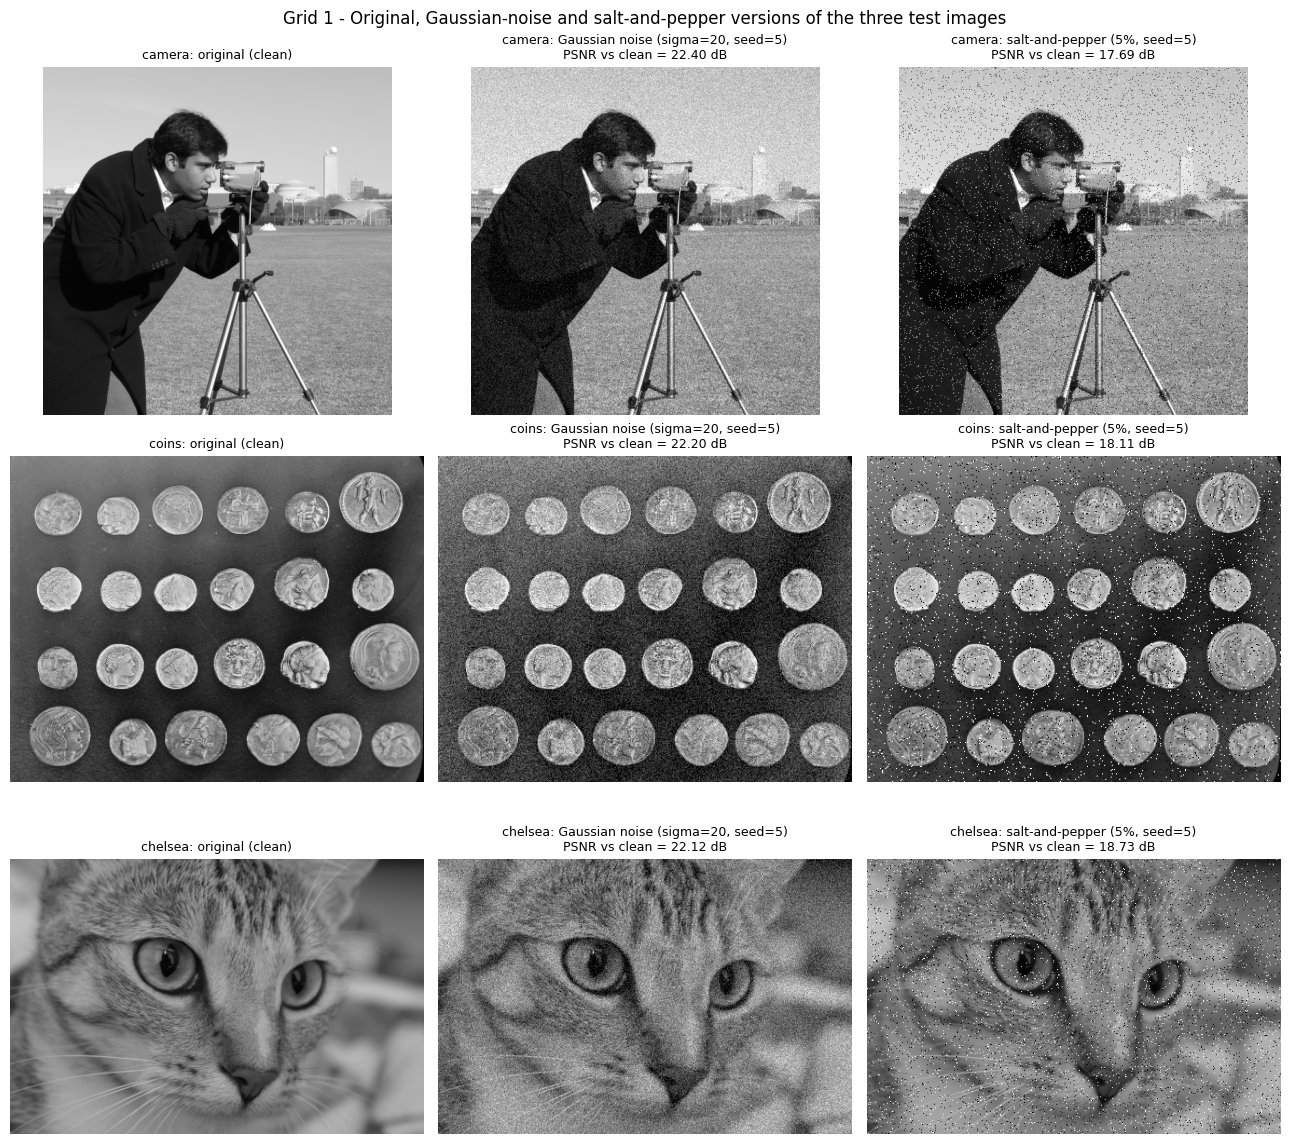

In [15]:
def show(ax, img, title):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for r, (name, clean) in enumerate(originals.items()):
    g, sp = noisy[(name, "gaussian")], noisy[(name, "salt_pepper")]
    show(axes[r, 0], clean, f"{name}: original (clean)")
    show(axes[r, 1], g,  f"{name}: Gaussian noise (sigma=20, seed=5)\nPSNR vs clean = {psnr(clean, g):.2f} dB")
    show(axes[r, 2], sp, f"{name}: salt-and-pepper (5%, seed=5)\nPSNR vs clean = {psnr(clean, sp):.2f} dB")
fig.suptitle("Grid 1 - Original, Gaussian-noise and salt-and-pepper versions of the three test images", fontsize=12)
plt.tight_layout()
fig.savefig("figures/grid1_noise_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

### Grid 2 — Mean vs Gaussian vs median (3×3) on every noisy image

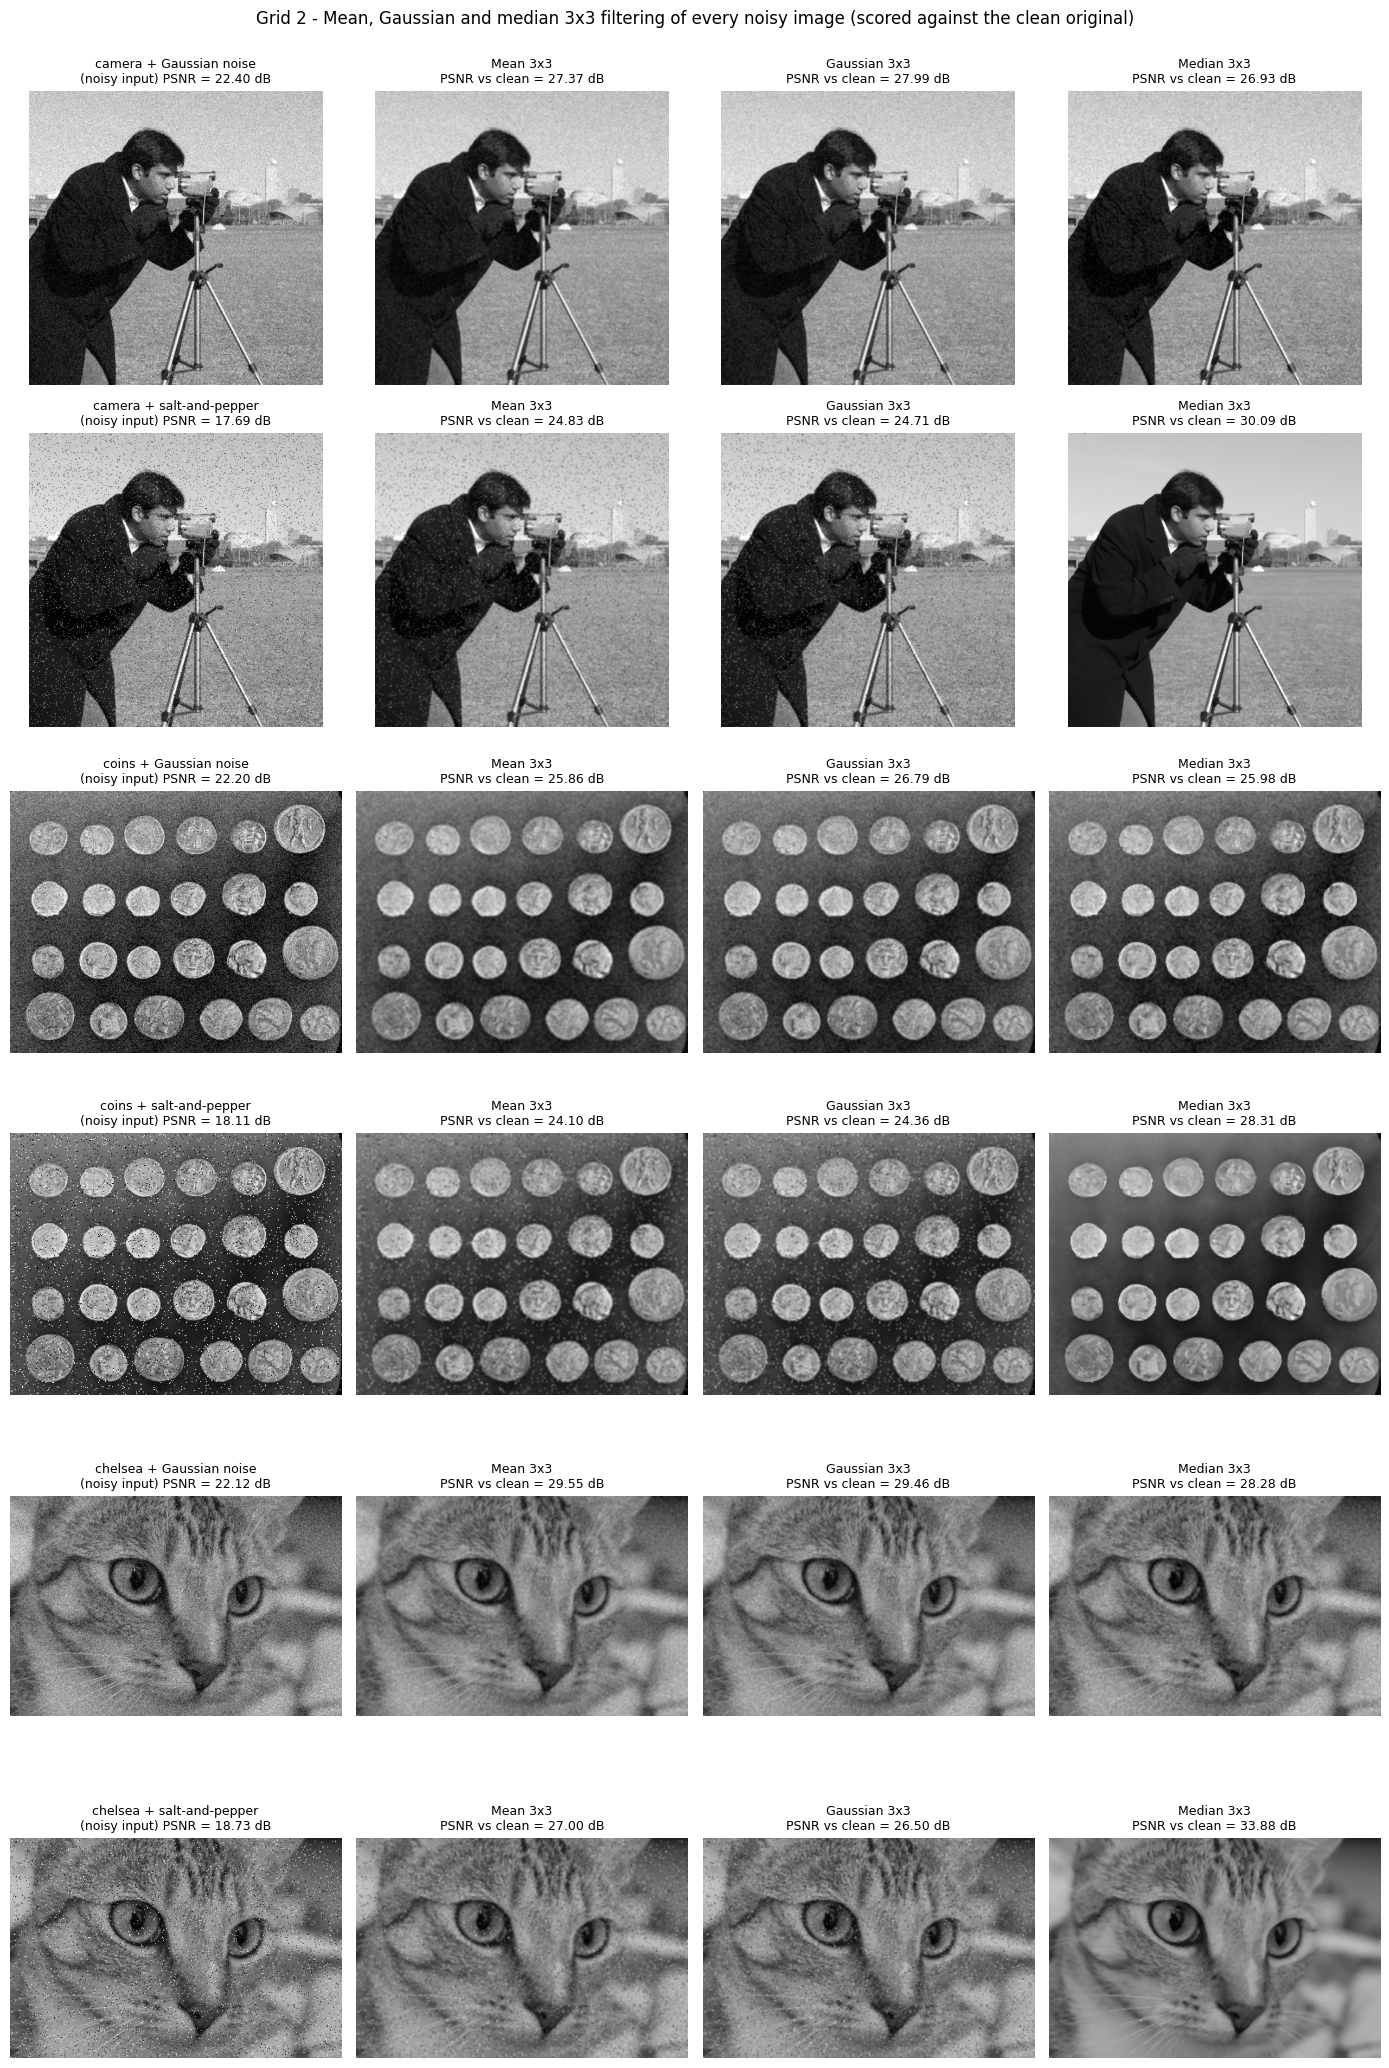

In [16]:
fig, axes = plt.subplots(6, 4, figsize=(14, 21))
for r, ((name, kind), noisy_img) in enumerate(noisy.items()):
    clean = originals[name]
    nice = "Gaussian noise" if kind == "gaussian" else "salt-and-pepper"
    show(axes[r, 0], noisy_img, f"{name} + {nice}\n(noisy input) PSNR = {psnr(clean, noisy_img):.2f} dB")
    for c, fname in enumerate(FILTERS, start=1):
        out = filtered[(name, kind, fname, 3)]
        show(axes[r, c], out, f"{fname} 3x3\nPSNR vs clean = {psnr(clean, out):.2f} dB")
fig.suptitle("Grid 2 - Mean, Gaussian and median 3x3 filtering of every noisy image (scored against the clean original)", fontsize=12, y=1.0)
plt.tight_layout()
fig.savefig("figures/grid2_filter_comparison_3x3.png", dpi=110, bbox_inches="tight")
plt.show()

### Grid 3 — Filter × kernel size (3×3, 5×5, 7×7) on the noisiest image

"Noisiest" is decided by the numbers, not by eye: it is the noisy image with the **lowest PSNR against its clean original**.

PSNR of every noisy image vs its clean original:
  camera   gaussian      22.40 dB
  camera   salt_pepper   17.69 dB
  coins    gaussian      22.20 dB
  coins    salt_pepper   18.11 dB
  chelsea  gaussian      22.12 dB
  chelsea  salt_pepper   18.73 dB

Noisiest image = camera / salt_pepper  (17.69 dB)


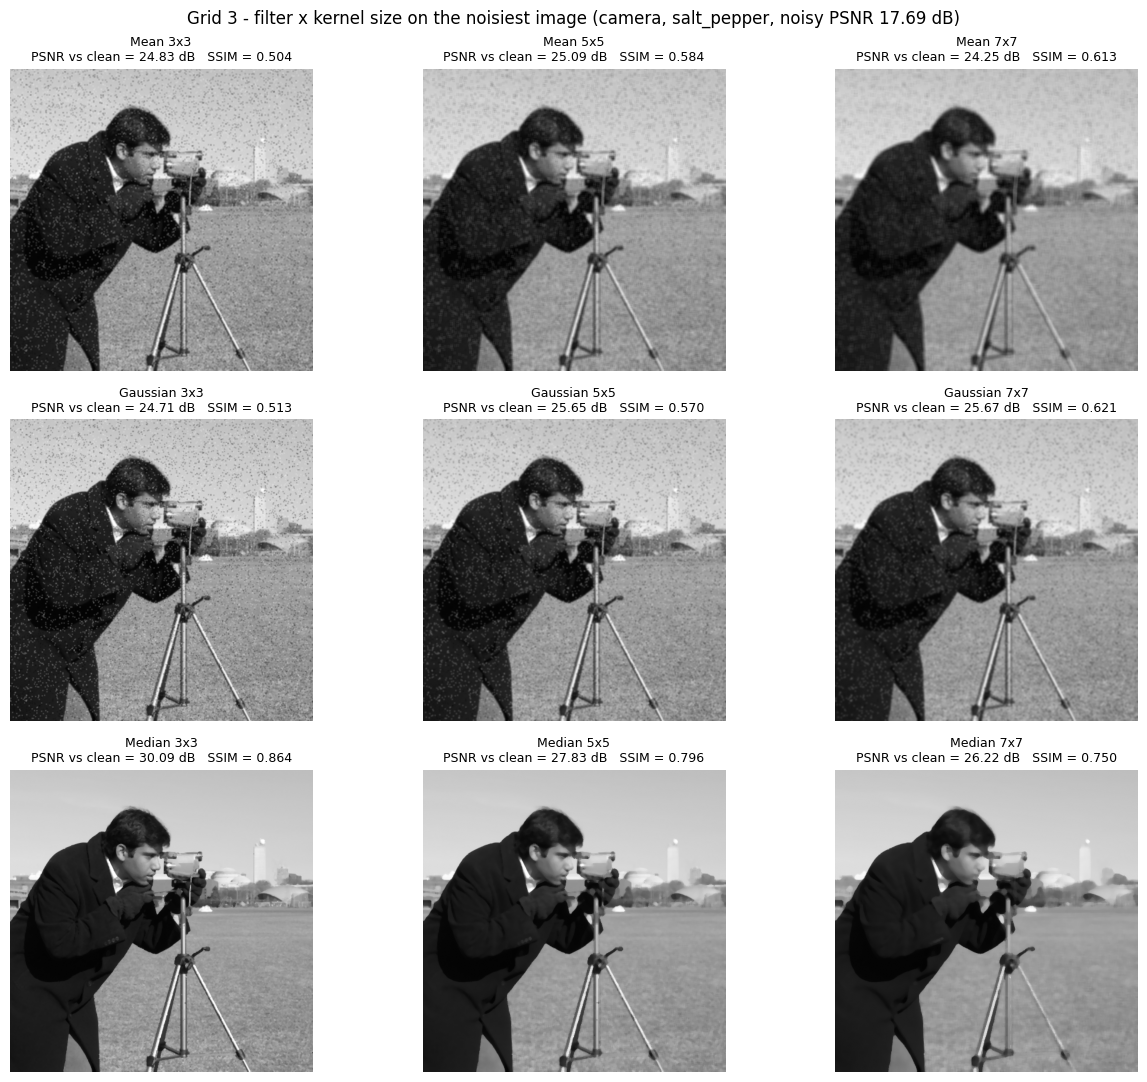

In [17]:
noisiest = min(noisy, key=lambda k: psnr(originals[k[0]], noisy[k]))
n_name, n_kind = noisiest
n_clean = originals[n_name]
print("PSNR of every noisy image vs its clean original:")
for k in noisy:
    print(f"  {k[0]:8s} {k[1]:12s} {psnr(originals[k[0]], noisy[k]):6.2f} dB")
print(f"\nNoisiest image = {n_name} / {n_kind}  ({psnr(n_clean, noisy[noisiest]):.2f} dB)")

fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for r, fname in enumerate(FILTERS):
    for c, size in enumerate(SIZES):
        out = filtered[(n_name, n_kind, fname, size)]
        show(axes[r, c], out, f"{fname} {size}x{size}\nPSNR vs clean = {psnr(n_clean, out):.2f} dB   SSIM = {ssim(n_clean, out):.3f}")
fig.suptitle(f"Grid 3 - filter x kernel size on the noisiest image ({n_name}, {n_kind}, noisy PSNR {psnr(n_clean, noisy[noisiest]):.2f} dB)", fontsize=12)
plt.tight_layout()
fig.savefig("figures/grid3_kernel_size_grid.png", dpi=110, bbox_inches="tight")
plt.show()

### Extra figure — a sharp edge and a region of fine detail (supports the observations)

Two regions of the `camera` image are examined closely, using the **Gaussian-noise** version filtered earlier:

* **Sharp edge:** the dark hair of the head against the bright sky (rows 60–110, columns 140–215).
* **Fine detail:** the thin tripod legs and feet (rows 340–440, columns 200–320).

The profile plot is taken from the *clean* image filtered with 5×5 mean and Gaussian (no noise), so the blur of the edge itself can be seen without the noise hiding it.

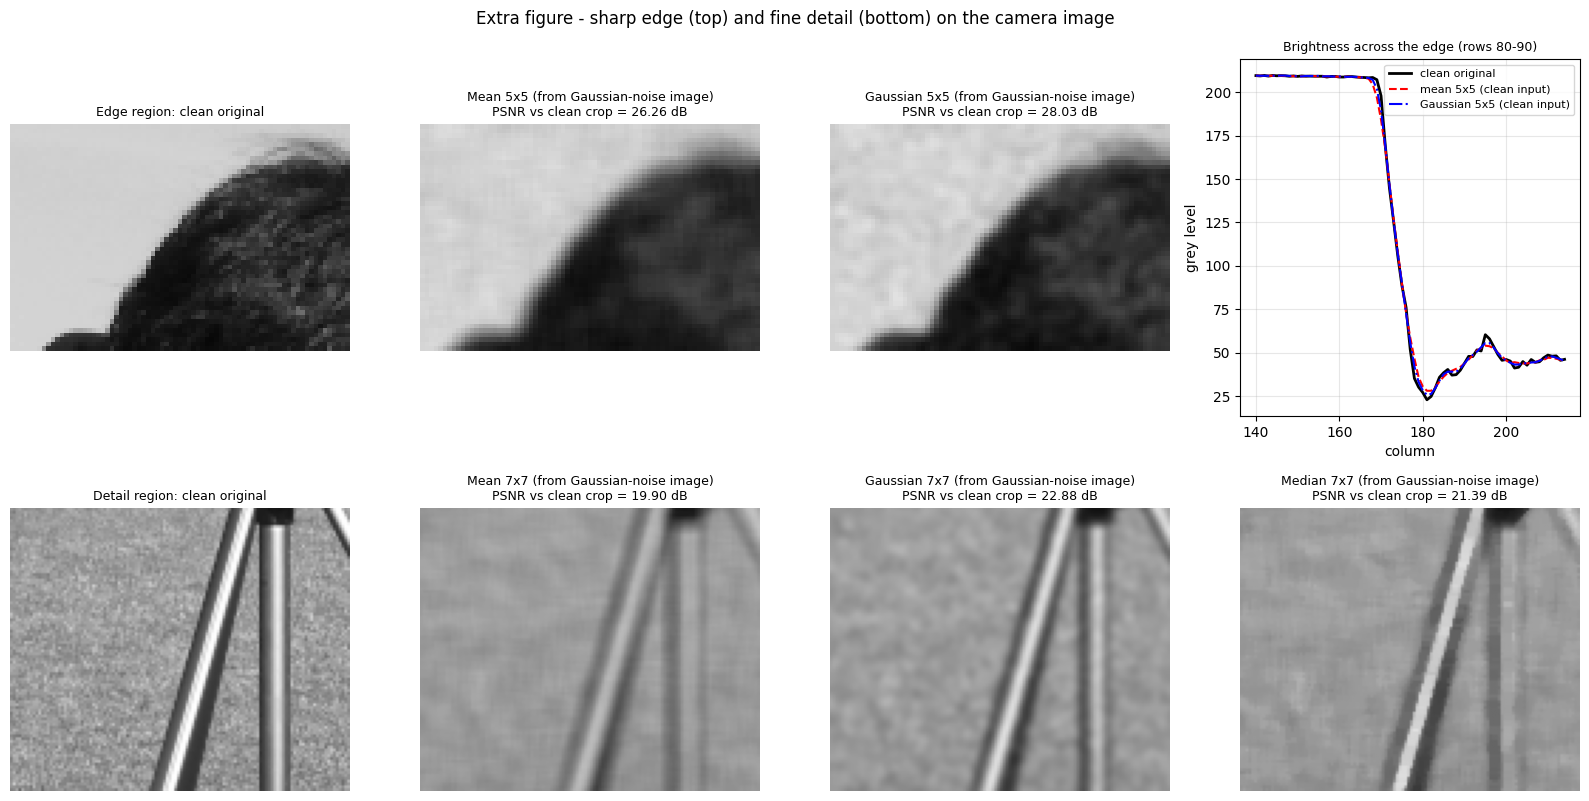

In [18]:
edge_r,   edge_c   = slice(60, 110),  slice(140, 215)      # head / sky edge
detail_r, detail_c = slice(340, 440), slice(200, 320)      # tripod feet

cam      = originals["camera"]
cam_gn   = noisy[("camera", "gaussian")]

def crop_title(label, img, region_r, region_c):
    return f"{label}\nPSNR vs clean crop = {psnr(cam[region_r, region_c], img[region_r, region_c]):.2f} dB"

fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
# row 1 - sharp edge (5x5)
show(axes[0, 0], cam[edge_r, edge_c], "Edge region: clean original")
show(axes[0, 1], filtered[("camera", "gaussian", "Mean", 5)][edge_r, edge_c],     crop_title("Mean 5x5 (from Gaussian-noise image)", filtered[("camera", "gaussian", "Mean", 5)], edge_r, edge_c))
show(axes[0, 2], filtered[("camera", "gaussian", "Gaussian", 5)][edge_r, edge_c], crop_title("Gaussian 5x5 (from Gaussian-noise image)", filtered[("camera", "gaussian", "Gaussian", 5)], edge_r, edge_c))

band = slice(80, 91)                                        # 11 rows averaged across the edge
cols_axis = np.arange(140, 215)
axes[0, 3].plot(cols_axis, cam[band, 140:215].astype(float).mean(axis=0), "k-", lw=2, label="clean original")
axes[0, 3].plot(cols_axis, mean_filter(cam, 5)[band, 140:215].astype(float).mean(axis=0), "r--", label="mean 5x5 (clean input)")
axes[0, 3].plot(cols_axis, gaussian_filter(cam, 5)[band, 140:215].astype(float).mean(axis=0), "b-.", label="Gaussian 5x5 (clean input)")
axes[0, 3].set_title("Brightness across the edge (rows 80-90)", fontsize=9)
axes[0, 3].set_xlabel("column"); axes[0, 3].set_ylabel("grey level"); axes[0, 3].legend(fontsize=8); axes[0, 3].grid(alpha=.3)

# row 2 - fine detail (7x7)
show(axes[1, 0], cam[detail_r, detail_c], "Detail region: clean original")
for c_idx, fname in enumerate(FILTERS, start=1):
    out = filtered[("camera", "gaussian", fname, 7)]
    show(axes[1, c_idx], out[detail_r, detail_c], crop_title(f"{fname} 7x7 (from Gaussian-noise image)", out, detail_r, detail_c))
fig.suptitle("Extra figure - sharp edge (top) and fine detail (bottom) on the camera image", fontsize=12)
plt.tight_layout()
fig.savefig("figures/extra_edge_and_detail.png", dpi=110, bbox_inches="tight")
plt.show()

## Observations and Results

### Numbers behind the observations
The cell below prints the measurements quoted in the answers, so every statement can be checked against the notebook's own output. All scores compare against the **clean original** (R6).

In [19]:
# 1) average PSNR over the three images at 3x3, per filter and noise type (vs clean original)
print("Average PSNR over the 3 images, 3x3 filters (dB, vs clean original)")
for kind in ("gaussian", "salt_pepper"):
    parts = []
    for fname in FILTERS:
        vals = [psnr(originals[n], filtered[(n, kind, fname, 3)]) for n in originals]
        parts.append(f"{fname}: {np.mean(vals):.2f}")
    base = np.mean([psnr(originals[n], noisy[(n, kind)]) for n in originals])
    print(f"  {kind:12s} noisy: {base:.2f} | " + " | ".join(parts))

# 2) steepest slope across the head/sky edge (grey levels per pixel; larger = sharper edge)
def steepest_slope(img):
    profile = img[80:91, 140:215].astype(float).mean(axis=0)
    return np.abs(np.diff(profile)).max()
print("\nSteepest slope across the head/sky edge (clean image filtered, grey levels per pixel)")
print(f"  clean original: {steepest_slope(cam):.1f}")
for size in SIZES:
    print(f"  {size}x{size}:  mean {steepest_slope(mean_filter(cam, size)):.1f}   Gaussian {steepest_slope(gaussian_filter(cam, size)):.1f}   median {steepest_slope(median_filter(cam, size)):.1f}")

# 3) fine detail (tripod feet): local PSNR / SSIM against the clean crop, Gaussian-noise camera
print("\nTripod-feet crop, Gaussian noise: local PSNR (dB) / SSIM vs clean crop")
for fname in FILTERS:
    parts = []
    for size in SIZES:
        out = filtered[("camera", "gaussian", fname, size)][detail_r, detail_c]
        parts.append(f"{size}x{size}: {psnr(cam[detail_r, detail_c], out):.2f} / {ssim(cam[detail_r, detail_c], out):.3f}")
    print(f"  {fname:8s}", "   ".join(parts))

# 4) whole-image PSNR on the noisiest image (camera / salt-and-pepper)
print("\nWhole-image PSNR on the noisiest image (camera / salt_pepper)")
for fname in FILTERS:
    print(f"  {fname:8s}", "   ".join(f"{s}x{s}: {psnr(cam, filtered[('camera', 'salt_pepper', fname, s)]):.2f}" for s in SIZES))

Average PSNR over the 3 images, 3x3 filters (dB, vs clean original)
  gaussian     noisy: 22.24 | Mean: 27.59 | Gaussian: 28.08 | Median: 27.07
  salt_pepper  noisy: 18.18 | Mean: 25.31 | Gaussian: 25.19 | Median: 30.76

Steepest slope across the head/sky edge (clean image filtered, grey levels per pixel)
  clean original: 28.2
  3x3:  mean 23.5   Gaussian 23.8   median 27.8
  5x5:  mean 20.9   Gaussian 22.4   median 27.4
  7x7:  mean 19.2   Gaussian 20.7   median 25.8

Tripod-feet crop, Gaussian noise: local PSNR (dB) / SSIM vs clean crop
  Mean     3x3: 24.32 / 0.603   5x5: 21.95 / 0.465   7x7: 19.90 / 0.351
  Gaussian 3x3: 25.57 / 0.695   5x5: 24.43 / 0.629   7x7: 22.88 / 0.546
  Median   3x3: 24.85 / 0.592   5x5: 23.43 / 0.491   7x7: 21.39 / 0.403

Whole-image PSNR on the noisiest image (camera / salt_pepper)
  Mean     3x3: 24.83   5x5: 25.09   7x7: 24.25
  Gaussian 3x3: 24.71   5x5: 25.65   7x7: 25.67
  Median   3x3: 30.09   5x5: 27.83   7x7: 26.22


### Answers to the five observation questions
*All answers are judged against the **clean original** (R6) and point to regions of this notebook's own figures and printed numbers.*

**1. Which filter looks best on Gaussian noise, and which looks worst?**
**Best: the Gaussian filter. Worst: the median filter** (judged on the 3×3 average). Averaged over the three images, the 3×3 Gaussian reaches **28.08 dB** against the clean original, the mean **27.59 dB** and the median **27.07 dB**. In Grid 2 the same order shows on the `camera` row (Gaussian 27.99 dB, mean 27.37 dB, median 26.93 dB) and on the `chelsea` row (29.46 / 29.55 / 28.28 dB for Gaussian / mean / median, so there mean and Gaussian are practically tied). Gaussian noise corrupts *every* pixel a little, so the best remedy is to average many neighbours. The median instead picks a single, still-noisy sample out of the window and averages nothing. One honest nuance: on the `coins` row the mean (25.86 dB) is a hair below the median (25.98 dB), and inside the tripod-feet crop of the extra figure the mean is the worst (24.32 dB vs 24.85 dB for the median) because it smears the thin legs.

**2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?**
**The median filter** is by far the best: on the `camera` salt-and-pepper row of Grid 2 the black and white specks on the coat and the sky are completely gone (30.09 dB), while the mean (24.83 dB) and the Gaussian (24.71 dB) columns still show the dots as grey smudges. Averaged over the three images the median scores 30.76 dB against 25.31 dB (mean) and 25.19 dB (Gaussian). The mean and Gaussian filters are *linear*: a 255 or a 0 pixel is simply added into the weighted sum, so it can only be diluted, never rejected. Dry-run Exercise 1 shows this exactly: one 255 among 40s gives 64 for the mean and 94 for the Gaussian, but 40 for the median. The Gaussian is even slightly worse than the mean here because it gives the centre pixel (the spike) the largest weight (4/16 vs 1/9). The median sorts the window; an impulse sits at one end of the sorted list and is never the middle value unless more than half of the window is corrupted, which at 5 % noise almost never happens.

**3. How do mean and Gaussian compare on a sharp edge?**
Look at the **head-against-sky edge** (top row of the extra figure, rows 80–90 in the profile plot). On the clean image the steepest slope is **28.2 grey levels per pixel**. After 5×5 filtering it drops to **20.9 for the mean but only 22.4 for the Gaussian**; the same ordering holds at 3×3 (23.5 vs 23.8) and 7×7 (19.2 vs 20.7). The Gaussian therefore keeps the edge sharper, and inside that crop the Gaussian 5×5 result is also closer to the clean image (28.03 dB vs 26.26 dB for the mean). The reason is the weights: the mean gives the far corners of the window the same weight as the centre, so dark hair and bright sky leak into each other; the Gaussian down-weights distant pixels. (The median keeps the edge sharpest of all: 27.4 at 5×5.)

**4. What happens to fine detail at 7×7?**
It is largely lost. In the bottom row of the extra figure the two thin **tripod legs** are smeared into soft grey bands: the local score against the clean crop falls from 24.32 dB (3×3) to **19.90 dB (7×7) for the mean**, from 25.57 dB to **22.88 dB for the Gaussian**, and from 24.85 dB to **21.39 dB for the median** (SSIM of the mean drops from 0.603 to 0.351). In the right-hand column of Grid 3 the same blurring shows in the tripod and in the buildings on the horizon, and the median's whole-image score on that image falls steadily from 30.09 dB (3×3) to 26.22 dB (7×7). A bigger window removes more noise but also removes real structure that is thinner than the window, so there is a trade-off; the mean and Gaussian whole-image scores flatten out or fall once the window reaches 7×7 (mean 25.09 → 24.25 dB).

**5. Why must the kernel size be odd?**
An odd kernel has a single centre pixel, so the output pixel sits exactly in the middle of its window, with equal padding on both sides. In the Task 4 experiment a single white pixel at (4, 4) blurred with a 3×3 mean gives a bright block on rows 3–5 and columns 3–5, centred on **(4.0, 4.0)** — the original position; with a 4×4 mean the block covers rows 3–6, columns 3–6 and is centred on **(4.5, 4.5)**, so the whole image would be shifted by half a pixel. Even sizes also need unequal (uneven) padding, and OpenCV simply refuses them for the median: `cv2.medianBlur(camera, 4)` raised an assertion error (`ksize % 2 == 1`) in the compliance check.

## Viva Preparation

**What is a kernel?** A small matrix of weights (here 3×3, 5×5 or 7×7) that slides over the image; each output pixel is the weighted sum of the neighbourhood under the kernel. The weights decide what the filter does (blur, sharpen, detect edges).

**Apply a 3×3 mean kernel to a 3×3 window given on the spot.** Add the nine values and divide by 9 (each weight is 1/9). Example from this notebook: the window `[[50,40,50],[20,10,20],[50,40,50]]` sums to 330, and 330 ÷ 9 = 36.67 ≈ 37.

**Why does the median remove a 255 spike but the mean does not?** The median sorts the nine values and takes the middle one, so one extreme value just sits at the end of the list and is ignored: `[40,…,40,255]` → 40. The mean adds the 255 to the sum (575 ÷ 9 ≈ 64), so the spike is only diluted, not removed.

**Why do the Gaussian weights sum to 16, and why divide by it?** The 3×3 weights are the outer product of 1-2-1 with itself: (1+2+1) × (1+2+1) = 16. Dividing by 16 makes the weights sum to 1 (R3), so a flat region keeps its brightness (a patch of 100s stays 100) instead of being brightened 16 times.

**Why do we pad the border before filtering?** Pixels on the edge have no neighbours outside the image. Padding (here reflect padding) supplies those missing neighbours, so every pixel can be filtered and the output keeps the same size as the input (R1). Reflect padding avoids the dark edge that zero padding would create.

**Which filter would you use for salt-and-pepper noise, and why?** The median filter: impulses are outliers and the median ignores outliers (30.09 dB vs about 24.8 dB for mean and Gaussian on the `camera` image in Grid 2).

## Final verification of the notebook

In [20]:
# The originals must be unchanged since Task 1 (R6 relies on them being the true clean images)
for name, im in originals.items():
    unchanged = hashlib.sha256(im.tobytes()).hexdigest() == fingerprints[name]
    print(f"{name:8s} unchanged since loading: {unchanged}   read-only: {not im.flags.writeable}")
    assert unchanged

print("\nFiles written by this notebook:")
for f in sorted(os.listdir("figures")):
    print("  figures/" + f)

camera   unchanged since loading: True   read-only: True
coins    unchanged since loading: True   read-only: True
chelsea  unchanged since loading: True   read-only: True

Files written by this notebook:
  figures/extra_edge_and_detail.png
  figures/grid1_noise_comparison.png
  figures/grid2_filter_comparison_3x3.png
  figures/grid3_kernel_size_grid.png


## Final Conclusion

* **Convolution from first principles works.** `conv2d_loop` (flipped kernel, reflect padding, float64) matches OpenCV to **1.1 × 10⁻¹³** in float64 with an asymmetric kernel, and to **0 grey levels** for the 3×3 mean on `camera`, so it agrees with OpenCV within rounding at every size tested; the flipped/unflipped comparison (maximum difference 83.3 without flipping) proves the flip is really performed.
* **Rules R1–R6 are satisfied and checked in code:** all 54 filtered images are `uint8`, 0–255 and the same shape as their input; every smoothing kernel sums to 1; even kernel sizes are rejected (`cv2.medianBlur(img, 4)` and our own wrappers); `seed=5` reproduces identical noisy images; and every score uses the clean original as reference.
* **Noise type decides the filter.** For Gaussian noise the Gaussian filter is best (28.08 dB average at 3×3 against 22.24 dB noisy); for salt-and-pepper noise the median is far ahead (30.76 dB against about 25.3 dB for the linear filters, from 18.18 dB noisy).
* **Larger kernels remove more noise but destroy detail:** at 7×7 the tripod legs are smeared, and the Gaussian keeps edges slightly sharper than the mean.
* **Dry-run exercises** were solved by hand in markdown (spike → mean 64, Gaussian 94, median 40; corner mean → 330 ÷ 9 ≈ 37) and confirmed by the notebook's own code.